# Lesson 34: Galvanostatic Techniques II: Chronocoulometry and Battery Testing
Controlling the current means controlling the rate at which charge is delivered, which means we know exactly how much charge has passed at every instant. That is a powerful thing to know, and it is the basis of essentially every measurement made on a real battery.

Today's topics:
- Chronocoulometry and differential charge analysis
- Galvanostatic cycling: capacity, C-rate and rate capability
- Coulombic efficiency, phase behaviour and cycle life

**Reference:**
- Sections 8.6 and 11.3 in *Electrochemical Methods: Fundamentals and Applications*, Allen J. Bard & Larry R. Faulkner.
---

## Configure Environment

In [1]:
import sys
if '../Resources' not in sys.path:
    sys.path.append('../Resources')     # so that echem.py can be found

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, widgets
from IPython.display import Image

import echem                            # the shared toolkit for this course
from echem import R, T, F, f, WIDE      # constants and the two-panel figure size
echem.use_style()                       # course-wide graph formatting

N_ELECTRONS = 1
E_QUARTER = 0.0                 # V, the potential at t = tau/4

# 6. Chronocoulometry

One of the primary benefits of chronopotentiometric techniques is that it facilitates your ability to pass a controlled amount of current at a controlled rate. We previously saw that current is simply the amount of charge passed per unit of time:

$ 
\large i = \frac{Q}{t}
$

Therefore, charge ($Q$) is readily defined as:

$
\large Q = i \cdot t
$

The amount of charge passed and time are therefore linearly related by the current selected. It is straightforward to integrate the constant current across the timeframe of the experiment to determine the charge. A differential plot comparing charge to voltage ($\delta Q / \delta E$) can then be generated, which looks quite similar to a voltammetric peak:

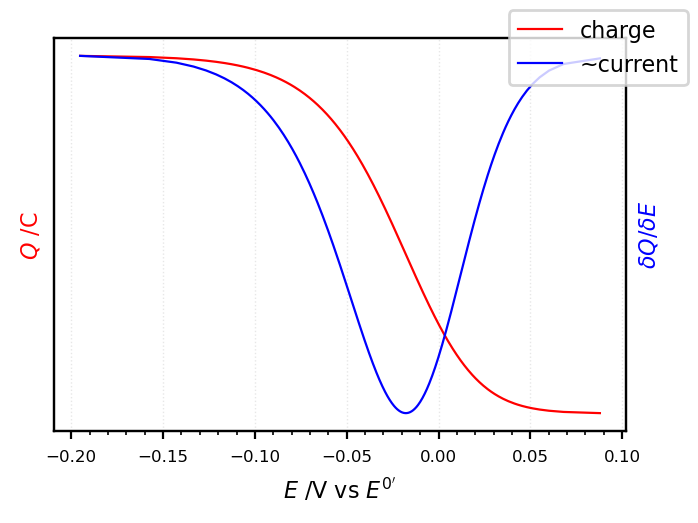

In [2]:
# Chronocoulometry.  At constant current, charge is simply Q = i t, so plotting
# Q against the potential the cell happens to be at converts an E-t curve into
# the charge-potential curve a battery scientist would recognise.
APPLIED_CURRENT = 1.0                           # A, taken as 1 so that Q = t
T_OVER_TAU = np.linspace(0.001, 0.999, 300)

potential = echem.chronopotentiogram(T_OVER_TAU, E_QUARTER, N_ELECTRONS)
charge = APPLIED_CURRENT*T_OVER_TAU             # Q = i t

fig = plt.figure()
ax1 = plt.subplot()
ax2 = ax1.twinx()

ax1.set_xlabel(r"$E$ /V vs $E^{0'}$")
ax1.set_ylabel(r'$Q$ /C', color='red')
ax1.set_yticks([])
ax1.plot(potential, charge, 'red', label='charge')

# dQ/dE peaks where the potential changes least per unit charge, which is where
# the redox process is happening.  This is the dQ/dV analysis used on batteries.
ax2.set_ylabel(r'$\delta Q / \delta E$', color='blue')
ax2.set_yticks([])
ax2.plot(potential, np.gradient(charge, potential), 'blue', label='~current')

fig.legend(fontsize=8)
fig.savefig('../Workspace/differential-charge.png')

# 7. Galvanostatic Cycling

Everything above was a single half-reaction at a single electrode. A battery is two of them facing each other, and the measurement that is run on one is exactly the experiment we have just derived: hold the current, watch the voltage.

Run it repeatedly, alternating sign, and you have **galvanostatic charge-discharge cycling**, which is how essentially every battery in the literature is characterised.

<div class="alert alert-block alert-success">
<b>Specific capacity</b>: the charge a material can store per unit mass, in mA h g$^{-1}$. It is the transition time of the previous section, expressed in the units a battery scientist uses.
</div>

The rate is quoted not as a current but as a **C-rate**, because the same current means very different things to a large cell and a small one.

<div class="alert alert-block alert-success">
<b>C-rate</b>: the current that would fully charge or discharge the cell in $1/C$ hours. 1C empties it in one hour, 2C in thirty minutes, C/10 in ten hours.
</div>

$ \large i = \text{capacity} \times C $

<div class="alert alert-block alert-danger">
<b>Check your units!</b>
<br>
A capacity in mA h multiplied by a dimensionless C-rate gives mA. Confirm for yourself that the hours cancel, and that a C-rate is really a reciprocal time in disguise.
</div>

In [3]:
CAPACITY = 150.0        # mA h g-1, a typical layered oxide cathode

print(f"{'C-rate':>8} {'current /mA g-1':>16} {'time to full':>14}")
for c_rate in [0.1, 0.5, 1.0, 2.0, 5.0, 10.0]:
    current = echem.c_rate_current(CAPACITY, c_rate)
    print(f'{c_rate:>7}C {current:>16.1f} {60/c_rate:>11.0f} min')

  C-rate  current /mA g-1   time to full
    0.1C             15.0         600 min
    0.5C             75.0         120 min
    1.0C            150.0          60 min
    2.0C            300.0          30 min
    5.0C            750.0          12 min
   10.0C           1500.0           6 min


# 8. What the Shape of the Curve Tells You

The voltage during discharge is set by the same equation we have been using all term. For an intercalation electrode, the fraction of lattice sites occupied, $x$, plays the part of the *reduced* species in a concentration ratio:

$ \large E = E^{0'} - \frac{RT}{nF} \ln \left( \frac{x}{1-x} \right) $

If the material stays in a single phase as $x$ changes, that expression is followed continuously and the discharge curve **slopes**. If instead the material separates into two phases, the phase rule fixes the chemical potential while both coexist, and the voltage does not move at all: the curve shows a **plateau**.

Take care with what happens at the two ends of that plateau, because it is easy to draw wrongly. Call the phase boundaries $x_1$ and $x_2$. Below $x_1$ only the $\alpha$ phase exists and the voltage follows the sloping expression above; between $x_1$ and $x_2$ the two phases coexist and the voltage sits on the plateau; above $x_2$ only $\beta$ remains and the slope returns.

The three pieces must **join continuously**. The chemical potential of lithium cannot jump at a phase boundary, since the two phases are in equilibrium with each other there, so each sloping branch has to arrive at the plateau voltage exactly as its phase runs out. A discharge curve drawn with a vertical step at $x_1$ or $x_2$ is not a battery, it is an arithmetic slip, and you will see it in print often enough to be worth recognising.

<div class="alert alert-block alert-info">
<b>Activity:</b> Grab a pen. Before running the cell below, sketch the discharge curve you expect for each case, with $E$ on the vertical axis and capacity on the horizontal.
<br>
Then sketch $\delta Q / \delta E$ underneath each one. What does a flat region in the first plot become in the second?
</div>

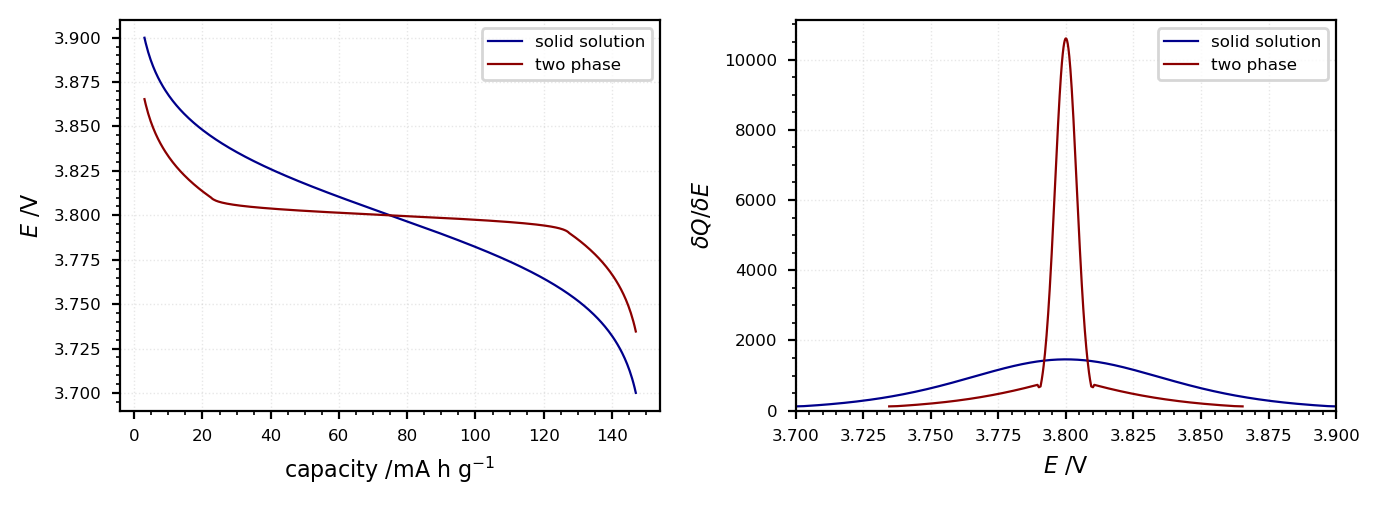

In [4]:
x = np.linspace(0.02, 0.98, 400)
capacity = CAPACITY*x                       # mA h g-1 delivered so far

fig = plt.figure(figsize=WIDE)
ax1 = plt.subplot(121)
ax2 = plt.subplot(122)

for label, voltage, colour in [
        ('solid solution', echem.solid_solution_voltage(x), 'darkblue'),
        ('two phase', echem.two_phase_voltage(x), 'darkred')]:
    ax1.plot(capacity, voltage, color=colour, label=label)
    # dQ/dE: large wherever the voltage is reluctant to move.  A discharge runs
    # downhill in E, so the derivative is negative; it is the MAGNITUDE that is
    # conventionally plotted, and that is what makes the comparison with a
    # voltammogram fair.
    ax2.plot(voltage, np.abs(np.gradient(capacity, voltage)), color=colour, label=label)

ax1.set_xlabel(r'capacity /mA h g$^{-1}$')
ax1.set_ylabel(r'$E$ /V')
ax1.legend(fontsize=6, loc=1)

ax2.set_xlabel(r'$E$ /V')
ax2.set_ylabel(r'$\delta Q / \delta E$')
ax2.set_xlim(3.7, 3.9)
ax2.set_ylim(bottom=0)
ax2.legend(fontsize=6, loc=1)

A plateau in the discharge curve becomes a **peak** in $\delta Q/\delta E$, and the sharper the phase transition the sharper the peak. This is the differential capacity analysis introduced in Section 6, applied to a device instead of a solution, and it is the standard way of watching a battery electrode change phase while it works.

Hopefully the resemblance is not lost on you. A peak that marks a redox process, sitting on a baseline, whose position reports thermodynamics and whose area reports charge: **this is a cyclic voltammogram in different clothes**.

Two details are worth a moment. Notice first that the red curve leaves and rejoins the sloping branches smoothly, exactly as the argument above requires: no steps at $x_1$ or $x_2$.

The second is in the right-hand panel, because it is the difference between the model and a measurement. because it is the difference between the model and a measurement. An **ideal** plateau is perfectly flat, and a perfectly flat plateau delivers all of its charge at a single voltage: $\delta Q/\delta E$ is infinite, and the curve cannot be drawn at all. The peak here is tall but finite because a real electrode is not one particle but billions, each with its own size, strain and contact resistance, so the transition happens over a **spread** of voltages rather than at one. `echem.two_phase_voltage` builds that spread in as a Gaussian 20 mV wide, and the peak you are looking at *is* that distribution: differentiate a cumulative Gaussian and you get the Gaussian back.

Two things follow. The **width** of the peak reports how uniform the electrode is, and the **area** reports the charge the transition carries. Watching the peak broaden and shrink over a few hundred cycles is one of the most direct ways of seeing an electrode degrade, and you are reading it off exactly the same axes as a voltammogram.

# 9. Efficiency and Cycle Life

Two cycles are never quite identical, and the difference is where the diagnosis lives.

<div class="alert alert-block alert-success">
<b>Coulombic efficiency</b>: the percentage of the charge put into a cell that comes back out on the following discharge. Anything short of 100 % means charge went somewhere other than the reaction you wanted.
</div>

The number sounds forgiving and is not. A cell losing 0.1 % of its charge every cycle is not 99.9 % healthy: after a thousand cycles it retains barely a third of its capacity.

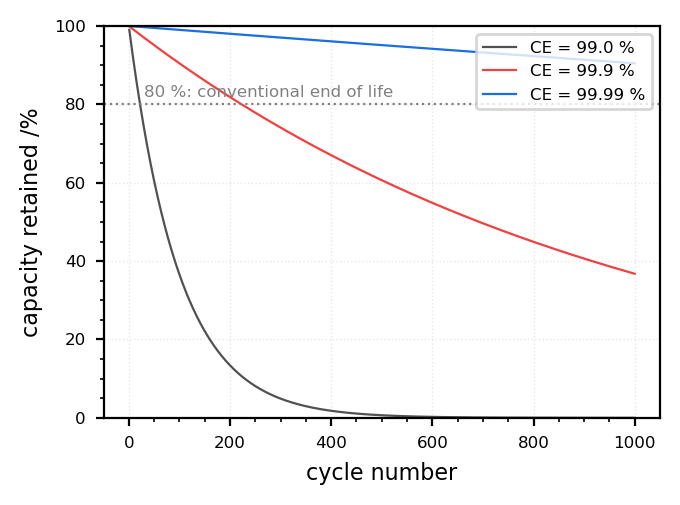

In [5]:
cycles = np.arange(1, 1001)

fig = plt.figure()
ax = plt.subplot()
for ce in [99.0, 99.9, 99.99]:
    ax.plot(cycles, 100*np.power(ce/100, cycles), label=f'CE = {ce} %')
ax.set_xlabel('cycle number')
ax.set_ylabel('capacity retained /%')
ax.set_ylim(0, 100)
ax.axhline(80, linestyle=':', color='gray')
ax.annotate('80 %: conventional end of life', (30, 82), fontsize=6, color='gray')
ax.legend(fontsize=6, loc=1)

<div class="alert alert-block alert-info">
<b>Activity:</b> Read the coulombic efficiency a cell would need in order to keep 80 % of its capacity after 1000 cycles off the figure above.
<br>
Now consider what that demands of your measurement. To distinguish a good cell from a fatal one, how precisely must you measure charge?
</div>

- Required CE for 1000 cycles: ANSWER
- Required precision in $Q$: ANSWER

<div class="alert alert-block alert-danger">
<b>Memory Check:</b> A cell tested at 5C delivers less capacity than the same cell at C/10. Name the three phenomena from earlier in this course that could each produce that result, and suggest one measurement that would separate them.
</div>

This is the whole course arriving at once. Solution resistance shifts the voltage and clips the usable window ([Lesson 7](L07-Resistance-DoubleLayer.ipynb)); slow electron transfer kinetics limit the rate at the interface ([Lesson 12](L12-Kinetics-II-Tafel.ipynb)); and solid-state diffusion inside the particle is a mass transport limitation of exactly the kind we spent four lessons on ([Lesson 14](L14-Mass-Transfer-Limitations.ipynb)). **Rate capability is a Ragone plot for one material**, and it is the answer to the question that opened the course in [Lesson 3](L03-Electrochemistry-Energy.ipynb).

# 10. Application to Battery Technologies

Many modern battery technologies require a redox-active solid-state material that is deposited on an electrode surface. The crystal structure must somehow accommodate the diffusion of ions (e.g., Li$^+$). This can be accomplished in a number of ways:
- Formation of a solid solution phase (real world example: Li$_x$TiS$_2$)
- First order transformation to a new phase (real world example: Li$_x$FePO$_4$)
- Transformation through an intermediate phase, then into the final phase (real world example: LiMn$_2$O$_4$)

Each of these situations presents different thermodynamics and mass-transfer considerations, which therefore yield different types of behavior. A description of these behaviors can be found in [2013 Acc. Chem. Res. 46, 1216-1225](https://pubs.acs.org/doi/10.1021/ar200329r)

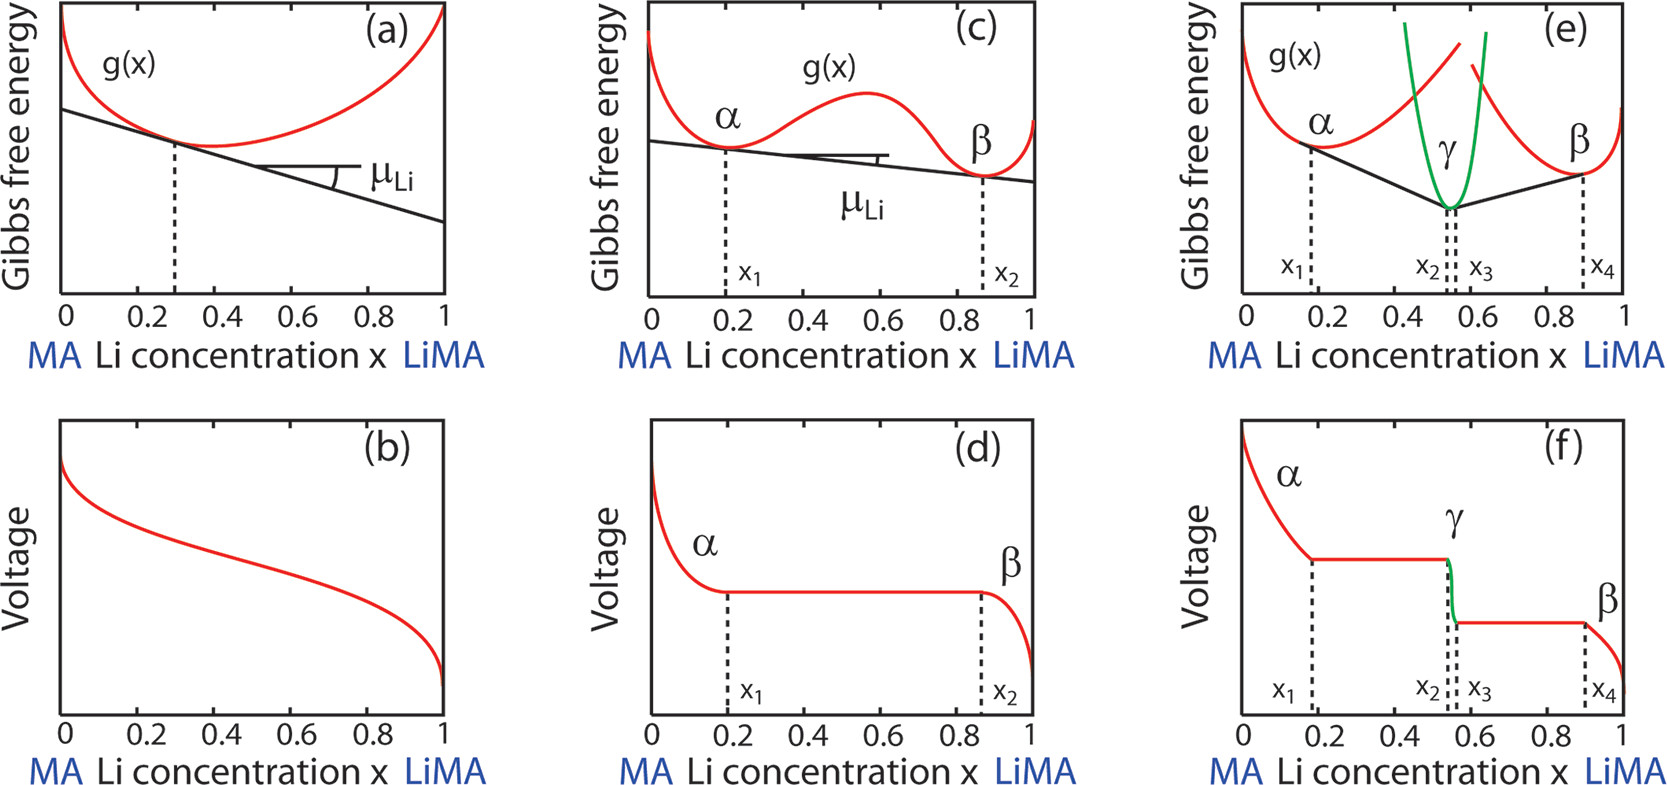

In [6]:
Image('../Resources/images/battery_behavior.jpeg')

The classic description of a lithium ion battery, for which the Nobel prize was recently awarded, is:

[2013 J. Am. Chem. Soc. 135, 1167](https://pubs.acs.org/doi/10.1021/ja3091438)

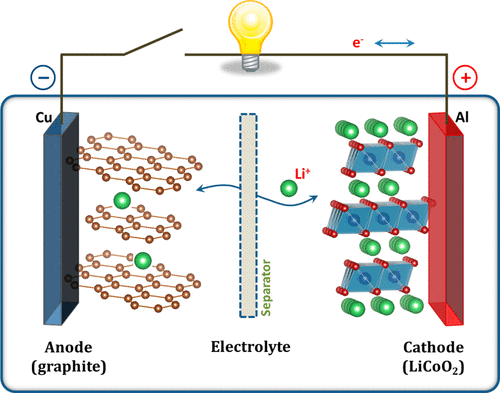

In [7]:
Image('../Resources/images/lib.gif')

An example of a battery that has two sequential redox couples, an Fe$^{II}$Fe$^{II}$/Fe$^{II}$Fe$^{III}$ followed by a Fe$^{II}$Fe$^{III}$/Fe$^{III}$Fe$^{III}$:

[2015 J. Am. Chem. Soc. 137, 2548](https://pubs.acs.org/doi/10.1021/ja510347s)

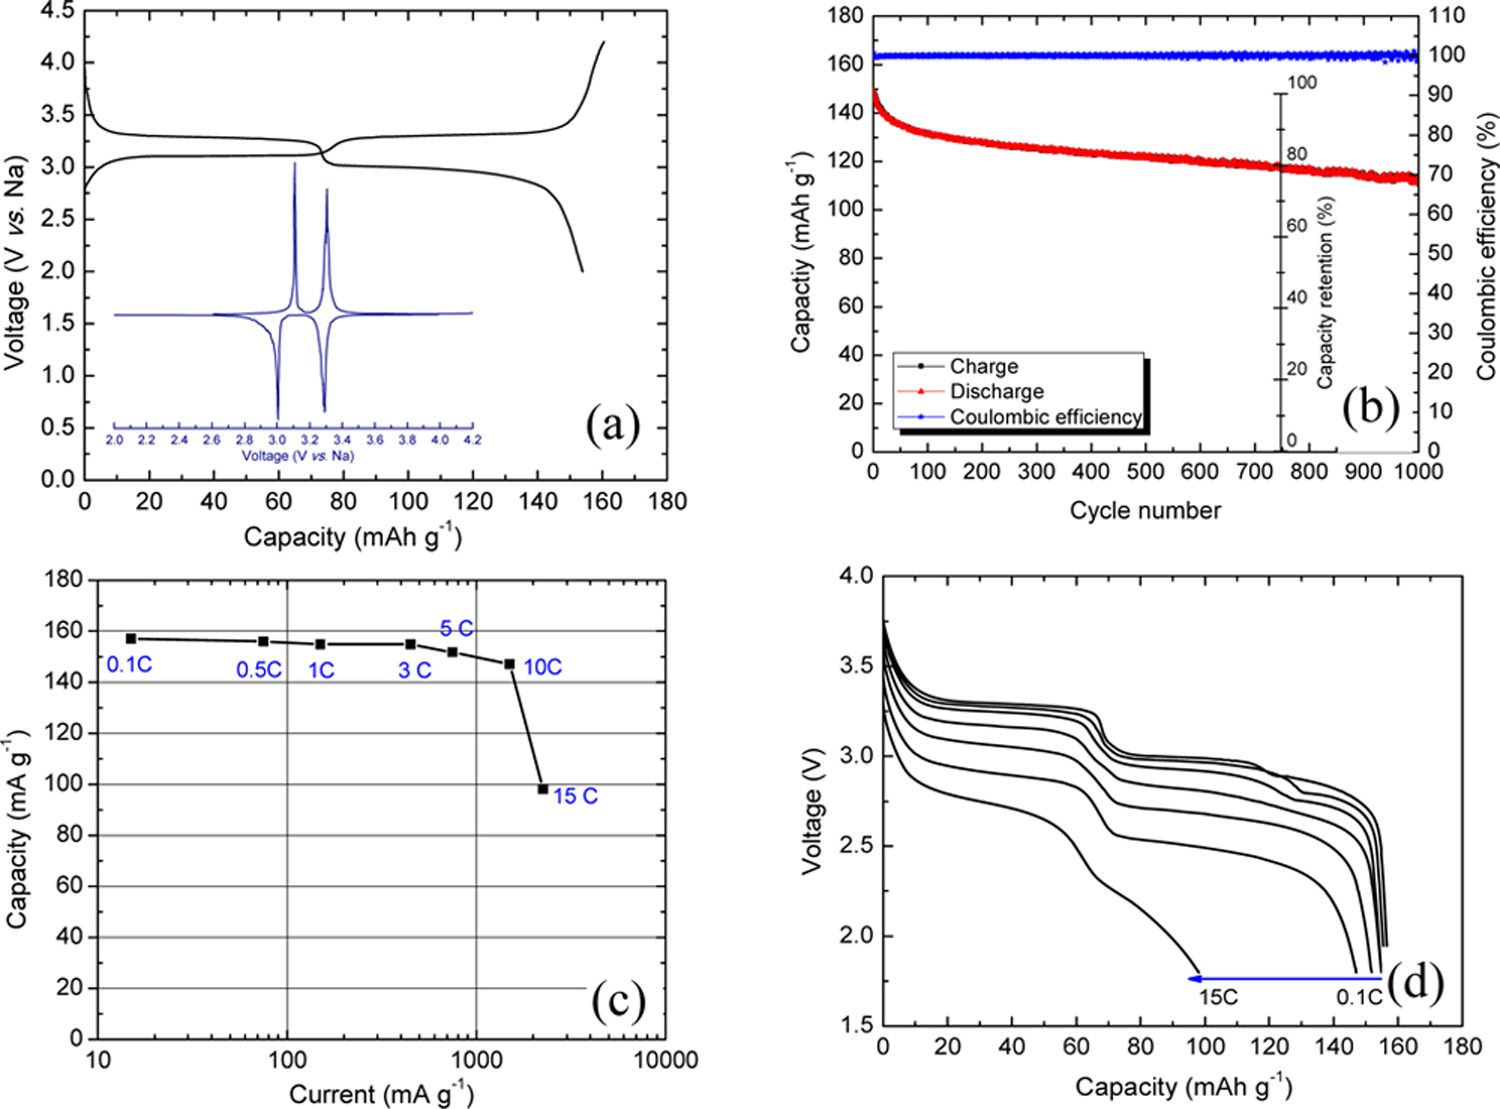

In [8]:
Image('../Resources/images/prussian.jpeg')

---
# Literature Examples

#### Phase transitions, watched as they happen

The phase behaviour sketched in Section 8 is not a modelling convenience. It is measured, and the structural changes that accompany it decide whether an electrode survives cycling at all.

- Li$_x$NiO$_2$ across the full composition range: [2018 J. Electrochem. Soc. 165, A2985](https://iopscience.iop.org/article/10.1149/2.0381813jes)
- Surface reconstruction of a perovskite oxide during oxygen evolution: [2012 J. Phys. Chem. Lett. 3, 3264](https://pubs.acs.org/doi/full/10.1021/jz301414z)

#### Further reading

- [2019 J. Phys. Chem. C 123, 25128](https://pubs.acs.org/doi/10.1021/acs.jpcc.9b05201): chemical dissolution of Pt(111) during potential cycling, followed by operando X-ray photoelectron spectroscopy.

<div class="alert alert-block alert-warning">
<b>Project Idea:</b> Any electrode material whose failure mode is structural rather than chemical makes a strong report topic. The measurement techniques are all ones you now recognise, and the literature is unusually willing to admit what it does not know.
</div>